In [1]:
import os
import pandas as pd
from aeon.visualisation import plot_critical_difference
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Full-shot experiments

## Univariate (Redux)

Datasets usados: 141


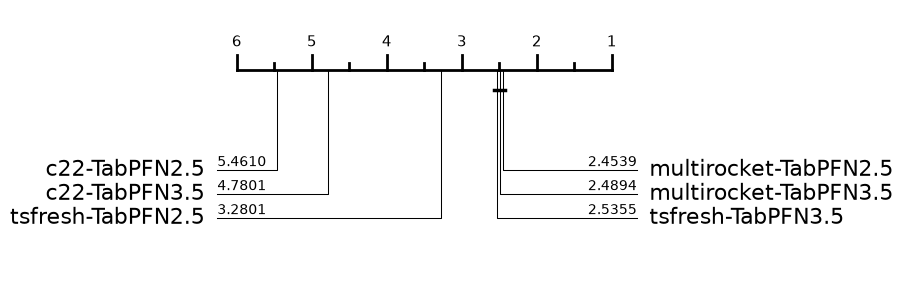

In [2]:
results_dir = "./full/redux/accuracy"

my_models = {
    "c22-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-c22_accuracy.csv"),
    "tsfresh-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    "c22-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-c22_accuracy.csv"),
    "tsfresh-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

results = {}

for model_name, path in my_models.items():
    # 1. Carregar garantindo o índice
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    
    # 2. Extrair apenas colunas numéricas e calcular a média
    mean_scores = df.select_dtypes(include="number").mean(axis=1)
    results[model_name] = mean_scores

# 3. Criar o DataFrame (Equivalente ao seu template de métricas)
combined = pd.DataFrame(results).dropna()

print("Datasets usados:", len(combined))


fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

Datasets usados: 121


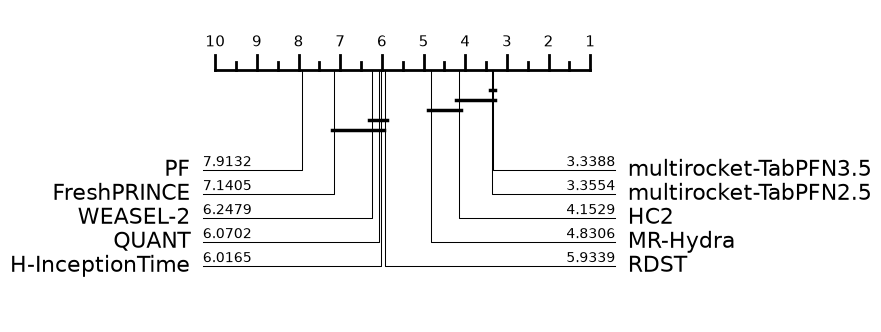

In [3]:
results_dir = "./full/redux/accuracy"

my_models = {
    "FreshPRINCE": os.path.join(results_dir, "FreshPRINCE_accuracy.csv"),
    "HC2": os.path.join(results_dir, "HC2_accuracy.csv"),
    "H-InceptionTime": os.path.join(
        results_dir, "H-InceptionTime_accuracy.csv"
    ),
    "MR-Hydra": os.path.join(results_dir, "MR-Hydra_accuracy.csv"),
    "PF": os.path.join(results_dir, "PF_accuracy.csv"),
    "QUANT": os.path.join(results_dir, "QUANT_accuracy.csv"),
    "RDST": os.path.join(results_dir, "RDST_accuracy.csv"),
    "WEASEL-2": os.path.join(results_dir, "WEASEL-2_accuracy.csv"),

    # "c22-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-c22_accuracy.csv"),
    # "tsfresh-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    # "c22-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-c22_accuracy.csv"),
    # "tsfresh-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

results = {}

for model_name, path in my_models.items():
    # 1. Carregar garantindo o índice
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    
    # 2. Extrair apenas colunas numéricas e calcular a média
    mean_scores = df.select_dtypes(include="number").mean(axis=1)
    results[model_name] = mean_scores

# 3. Criar o DataFrame (Equivalente ao seu template de métricas)
combined = pd.DataFrame(results).dropna()

print("Datasets usados:", len(combined))

fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

                       datasets  mediana (MB)  média (MB)  máx (MB)
TabPFN2.5-c22             141.0         78.63      106.86    726.71
TabPFN2.5-tsfresh         141.0        408.45      537.92   3719.35
TabPFN2.5-multirocket     141.0        273.14      497.45   5221.39
TabPFN3.5-c22             141.0        923.51      948.66   1217.71
TabPFN3.5-tsfresh         141.0       2582.58     3085.80   6677.81
TabPFN3.5-multirocket     141.0       2782.49     3368.49   7207.49


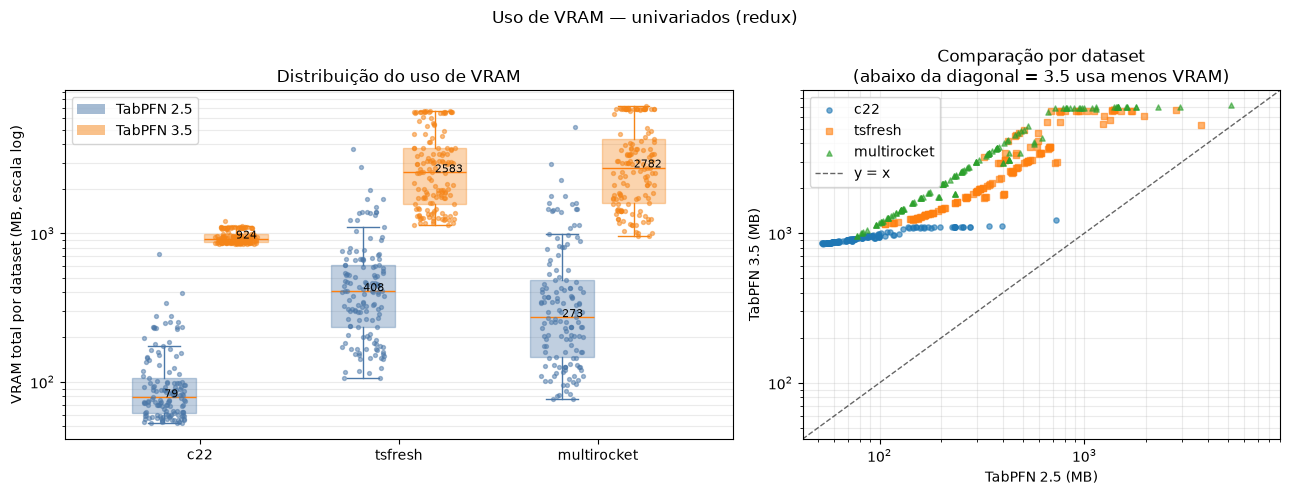

In [4]:
base, stat = Path("./full/redux"), "vram_total_mb"
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}
data = {}

for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if p.exists():
            df = pd.read_csv(p, index_col=0).select_dtypes("number")
            data[v, m] = df.mean(axis=1).rename(str)
        else:
            print(f"Não encontrado: {p}")

summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(), "mediana (MB)": s.median(),
        "média (MB)": s.mean(), "máx (MB)": s.max()
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        y = y[y > 0]
        if not len(y):
            continue
        pos = i + (j - (len(versions)-1)/2) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.0f}", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="VRAM total por dataset (MB, escala log)",
      title="Distribuição do uso de VRAM")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6,
              marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (MB)",
      ylabel="TabPFN 3.5 (MB)",
      title="Comparação por dataset\n(abaixo da diagonal = 3.5 usa menos VRAM)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Uso de VRAM — univariados (redux)")
plt.tight_layout()
plt.show()

                       datasets  mediana (s)  média (s)  máx (s)  total (min)
TabPFN2.5-c22             141.0         3.61       5.15    28.31        12.09
TabPFN2.5-tsfresh         141.0         7.71      26.04   345.61        61.19
TabPFN2.5-multirocket     141.0        31.45     125.14  1591.93       294.07
TabPFN3.5-c22             141.0         3.80       4.31    16.41        10.13
TabPFN3.5-tsfresh         141.0         6.81      11.20    84.21        26.31
TabPFN3.5-multirocket     141.0        11.50      15.94   126.21        37.45


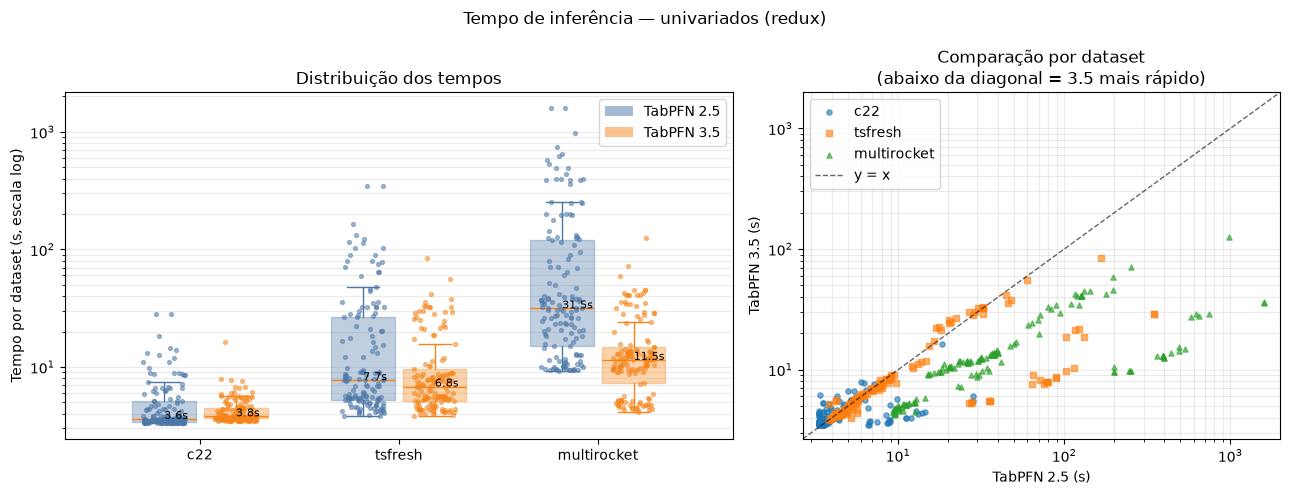

In [5]:
base, stat = Path("./full/redux"), "inference_time"
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}
data = {}

for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if p.exists():
            df = pd.read_csv(p, index_col=0).select_dtypes("number")
            data[v, m] = df.mean(axis=1).rename(str)
        else:
            print(f"Não encontrado: {p}")

summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(), "mediana (s)": s.median(),
        "média (s)": s.mean(), "máx (s)": s.max(), "total (min)": s.sum()/60
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        if not len(y):
            continue
        pos = i + (j - (len(versions)-1)/2) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.1f}s", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="Tempo por dataset (s, escala log)", title="Distribuição dos tempos")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6, marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (s)",
      ylabel="TabPFN 3.5 (s)", title="Comparação por dataset\n(abaixo da diagonal = 3.5 mais rápido)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Tempo de inferência — univariados (redux)")
plt.tight_layout()
plt.show()

## Multivariate (Multiverse core - 1 run)

Datasets usados: 56


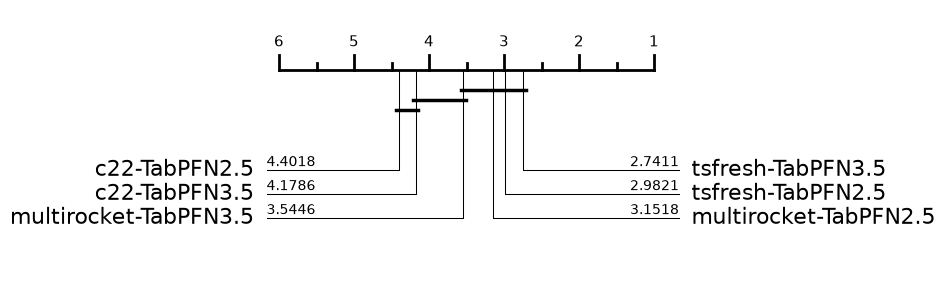

In [6]:
results_dir = "./full/mv_core/accuracy"

my_models = {
    "c22-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-c22_accuracy.csv"),
    "tsfresh-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    "c22-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-c22_accuracy.csv"),
    "tsfresh-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

results = {}

for model_name, path in my_models.items():
    # 1. Carregar garantindo o índice
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    
    # 2. Extrair apenas colunas numéricas e calcular a média
    scores = df[0] if 0 in df.columns else df["0"]
    results[model_name] = scores

# 3. Criar o DataFrame (Equivalente ao seu template de métricas)
combined = pd.DataFrame(results).dropna()

print("Datasets usados:", len(combined))

fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

Datasets usados: 54


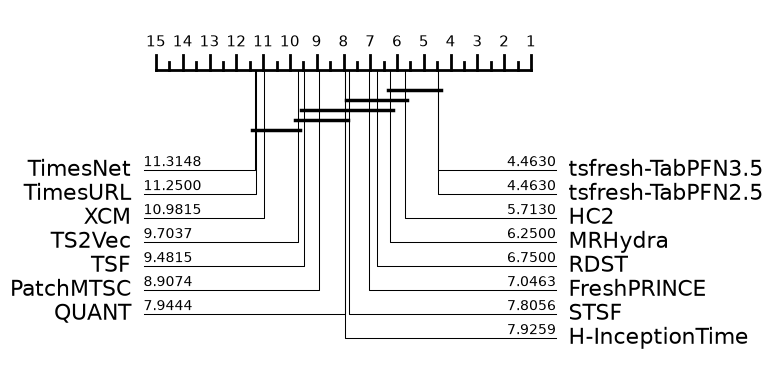

In [7]:
results_dir = "./full/mv_core/accuracy"

my_models = {
    "FreshPRINCE": os.path.join(results_dir, "FreshPRINCE_accuracy.csv"),
    "HC2": os.path.join(results_dir, "HC2_accuracy.csv"),
    "H-InceptionTime": os.path.join(results_dir, "H-InceptionTime_accuracy.csv"),
    "MRHydra": os.path.join(results_dir, "MRHydra_accuracy.csv"),
    "QUANT": os.path.join(results_dir, "QUANT_accuracy.csv"),
    "RDST": os.path.join(results_dir, "RDST_accuracy.csv"),
    "TSF": os.path.join(results_dir, "TSF_accuracy.csv"),
    "STSF": os.path.join(results_dir, "STSF_accuracy.csv"),
    "PatchMTSC": os.path.join(results_dir, "PatchMTSC_accuracy.csv"),
    "TS2Vec": os.path.join(results_dir, "TS2Vec_accuracy.csv"),
    "TimesNet": os.path.join(results_dir, "TimesNet_accuracy.csv"),
    "TimesURL": os.path.join(results_dir, "TimesURL_accuracy.csv"),
    "XCM": os.path.join(results_dir, "XCM_accuracy.csv"),

    # "c22-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-c22_accuracy.csv"),
    "tsfresh-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    # "multirocket-TabPFN3.5": os.path.join(results_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    # "c22-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-c22_accuracy.csv"),
    "tsfresh-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    # "multirocket-TabPFN2.5": os.path.join(results_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

results = {}

for model_name, path in my_models.items():
    # 1. Carregar garantindo o índice
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    
    # 2. Extrair apenas colunas numéricas e calcular a média
    scores = df[0] if 0 in df.columns else df["0"]
    results[model_name] = scores

# 3. Criar o DataFrame (Equivalente ao seu template de métricas)
combined = pd.DataFrame(results).dropna()

print("Datasets usados:", len(combined))

fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

                       datasets  mediana (MB)  média (MB)  máx (MB)
TabPFN2.5-c22              56.0        257.57      577.10   2463.41
TabPFN2.5-tsfresh          56.0        355.19      762.56   3911.30
TabPFN2.5-multirocket      56.0        283.95      922.11   5382.19
TabPFN3.5-c22              56.0       1374.53     1673.00   4694.22
TabPFN3.5-tsfresh          56.0       2487.24     3212.97   6925.12
TabPFN3.5-multirocket      56.0       2616.42     3616.67   7212.92


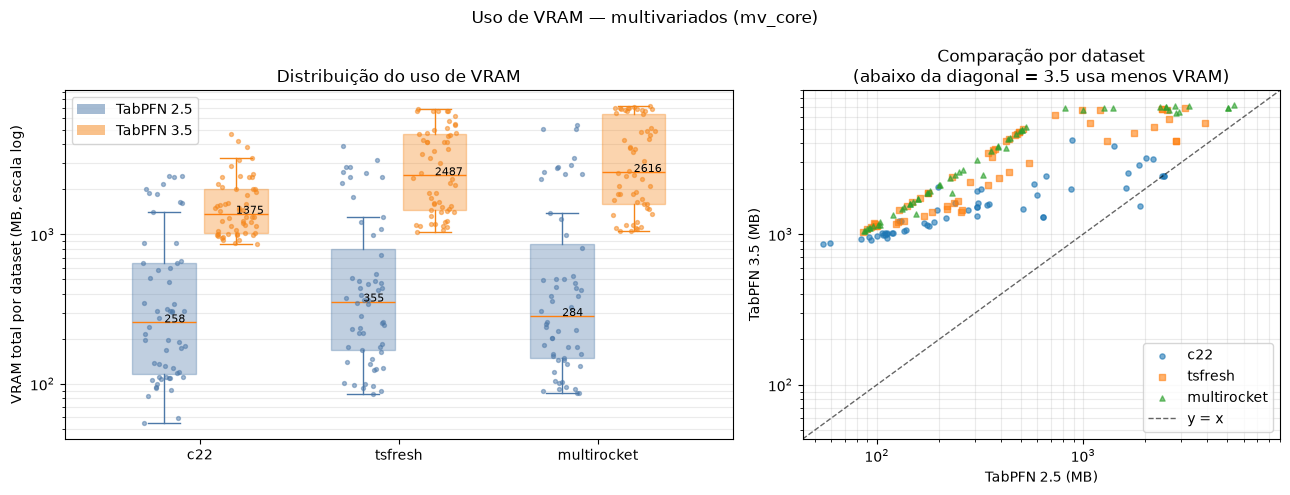

In [14]:
base, stat = Path("./full/mv_core"), "vram_total_mb"
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}
data = {}

for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if p.exists():
            df = pd.read_csv(p, index_col=0).select_dtypes("number")
            data[v, m] = df.mean(axis=1).rename(str)
        else:
            print(f"Não encontrado: {p}")

summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(), "mediana (MB)": s.median(),
        "média (MB)": s.mean(), "máx (MB)": s.max()
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        y = y[y > 0]
        if not len(y):
            continue
        pos = i + (j - (len(versions)-1)/2) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.0f}", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="VRAM total por dataset (MB, escala log)",
      title="Distribuição do uso de VRAM")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6,
              marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (MB)",
      ylabel="TabPFN 3.5 (MB)",
      title="Comparação por dataset\n(abaixo da diagonal = 3.5 usa menos VRAM)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Uso de VRAM — multivariados (mv_core)")
plt.tight_layout()
plt.show()

                       datasets  mediana (s)  média (s)  máx (s)  total (min)
TabPFN2.5-c22              56.0         4.49      10.89   127.67        10.16
TabPFN2.5-tsfresh          56.0         8.33      31.82   491.07        29.70
TabPFN2.5-multirocket      56.0        14.89     100.70   850.88        93.99
TabPFN3.5-c22              56.0         3.92       5.21    20.67         4.86
TabPFN3.5-tsfresh          56.0         5.86       9.73    39.83         9.08
TabPFN3.5-multirocket      56.0         8.02      13.33    68.53        12.44


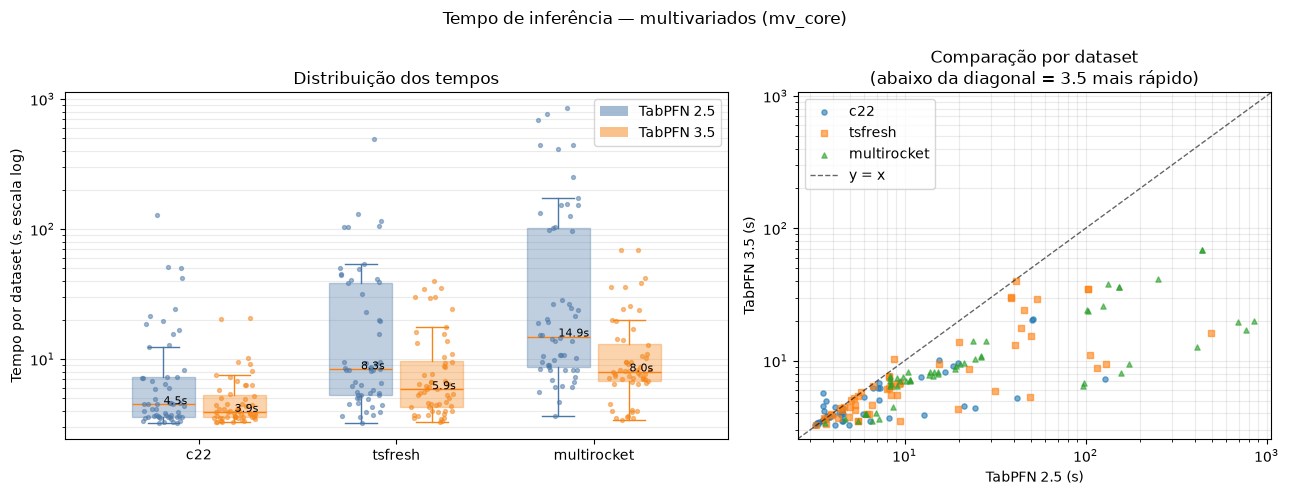

In [15]:
base, stat = Path("./full/mv_core"), "inference_time"
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}
data = {}

for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if p.exists():
            df = pd.read_csv(p, index_col=0).select_dtypes("number")
            data[v, m] = df.mean(axis=1).rename(str)
        else:
            print(f"Não encontrado: {p}")

summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(), "mediana (s)": s.median(),
        "média (s)": s.mean(), "máx (s)": s.max(), "total (min)": s.sum()/60
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        if not len(y):
            continue
        pos = i + (j - (len(versions)-1)/2) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.1f}s", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="Tempo por dataset (s, escala log)", title="Distribuição dos tempos")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6, marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (s)",
      ylabel="TabPFN 3.5 (s)", title="Comparação por dataset\n(abaixo da diagonal = 3.5 mais rápido)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Tempo de inferência — multivariados (mv_core)")
plt.tight_layout()
plt.show()

## Multivariate (UEA - 30 runs)

No DTW mas não nos seus resultados: ['BasicMotions', 'FaceDetection', 'FingerMovements', 'Heartbeat', 'PenDigits', 'SelfRegulationSCP2']
Datasets usados: 20


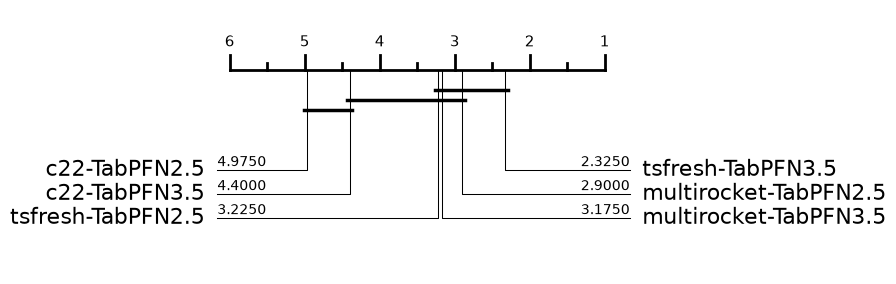

In [10]:
results_dir = "./full/uea/accuracy"
tabpfn_dir = "./full/mv_core/accuracy"

# Ajuste o nome do arquivo do 1NN-DTW-A conforme está na sua pasta
dtw_path = os.path.join(results_dir, "1NN-DTW-D_accuracy.csv")

my_models = {
    "c22-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-c22_accuracy.csv"),
    "tsfresh-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    "c22-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-c22_accuracy.csv"),
    "tsfresh-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

# 1. Datasets que o 1NN-DTW-A rodou (média por dataset, ignorando linhas vazias)
dtw = pd.read_csv(dtw_path, index_col=0)
dtw.index = dtw.index.astype(str)
dtw_datasets = dtw.select_dtypes(include="number").mean(axis=1).dropna().index

# 2. Seus modelos
results = {}

for model_name, path in my_models.items():
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    mean_scores = df.select_dtypes(include="number").mean(axis=1)
    results[model_name] = mean_scores

combined = pd.DataFrame(results)

# 3. Filtra só os datasets do 1NN-DTW-A e depois remove os incompletos
common = combined.index.intersection(dtw_datasets)
combined = combined.loc[common].dropna()

# Checagem: datasets do DTW que não apareceram nos seus (nome diferente ou run faltando)
missing = dtw_datasets.difference(combined.index)
if len(missing) > 0:
    print("No DTW mas não nos seus resultados:", sorted(missing))

print("Datasets usados:", len(combined))

fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

Datasets usados: 15


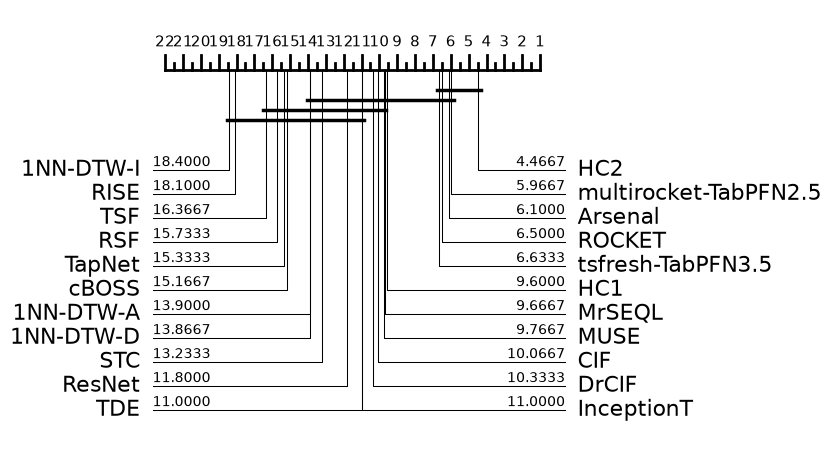

In [11]:
results_dir = "./full/uea/accuracy"
tabpfn_dir = "./full/mv_core/accuracy"

my_models = {
    "1NN-DTW-A": os.path.join(results_dir, "1NN-DTW-A_accuracy.csv"),
    "1NN-DTW-D": os.path.join(results_dir, "1NN-DTW-D_accuracy.csv"),
    "1NN-DTW-I": os.path.join(results_dir, "1NN-DTW-I_accuracy.csv"),
    "Arsenal": os.path.join(results_dir, "Arsenal_accuracy.csv"),
    "cBOSS": os.path.join(results_dir, "cBOSS_accuracy.csv"),
    "CIF": os.path.join(results_dir, "CIF_accuracy.csv"),
    "DrCIF": os.path.join(results_dir, "DrCIF_accuracy.csv"),
    "HC1": os.path.join(results_dir, "HC1_accuracy.csv"),
    "HC2": os.path.join(results_dir, "HC2_accuracy.csv"),
    "InceptionT": os.path.join(results_dir, "InceptionT_accuracy.csv"),
    "MrSEQL": os.path.join(results_dir, "MrSEQL_accuracy.csv"),
    "MUSE": os.path.join(results_dir, "MUSE_accuracy.csv"),
    "ResNet": os.path.join(results_dir, "ResNet_accuracy.csv"),
    "RISE": os.path.join(results_dir, "RISE_accuracy.csv"),
    "ROCKET": os.path.join(results_dir, "ROCKET_accuracy.csv"),
    "RSF": os.path.join(results_dir, "RSF_accuracy.csv"),
    "STC": os.path.join(results_dir, "STC_accuracy.csv"),
    "TapNet": os.path.join(results_dir, "TapNet_accuracy.csv"),
    "TDE": os.path.join(results_dir, "TDE_accuracy.csv"),
    "TSF": os.path.join(results_dir, "TSF_accuracy.csv"),

    # "c22-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-c22_accuracy.csv"),
    "tsfresh-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-tsfresh_accuracy.csv"),
    # "multirocket-TabPFN3.5": os.path.join(tabpfn_dir, "TabPFN3.5-multirocket_accuracy.csv"),

    # "c22-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-c22_accuracy.csv"),
    # "tsfresh-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-tsfresh_accuracy.csv"),
    "multirocket-TabPFN2.5": os.path.join(tabpfn_dir, "TabPFN2.5-multirocket_accuracy.csv"),
}

metric_name = "Accuracy"

results = {}

for model_name, path in my_models.items():
    # 1. Carregar garantindo o índice
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    
    # 2. Extrair apenas colunas numéricas e calcular a média
    mean_scores = df.select_dtypes(include="number").mean(axis=1)
    results[model_name] = mean_scores

# 3. Criar o DataFrame (Equivalente ao seu template de métricas)
combined = pd.DataFrame(results).dropna()

print("Datasets usados:", len(combined))

fig, ax = plot_critical_difference(
    combined.to_numpy(),
    combined.columns.tolist(),
    test="wilcoxon",
    alpha=0.05,
)

                       datasets  mediana (MB)  média (MB)  máx (MB)
TabPFN2.5-c22              20.0        111.44      305.46   1860.77
TabPFN2.5-tsfresh          20.0        233.90      419.70   3126.13
TabPFN2.5-multirocket      20.0        179.01      434.80   2931.59
TabPFN3.5-c22              20.0       1025.68     1289.75   2870.92
TabPFN3.5-tsfresh          20.0       1625.90     2119.01   6925.12
TabPFN3.5-multirocket      20.0       1872.99     2366.02   6964.64

Datasets no UEA: 26
TabPFN 2.5 + c22: 20/26
TabPFN 2.5 + tsfresh: 20/26
TabPFN 2.5 + multirocket: 20/26
TabPFN 3.5 + c22: 20/26
TabPFN 3.5 + tsfresh: 20/26
TabPFN 3.5 + multirocket: 20/26


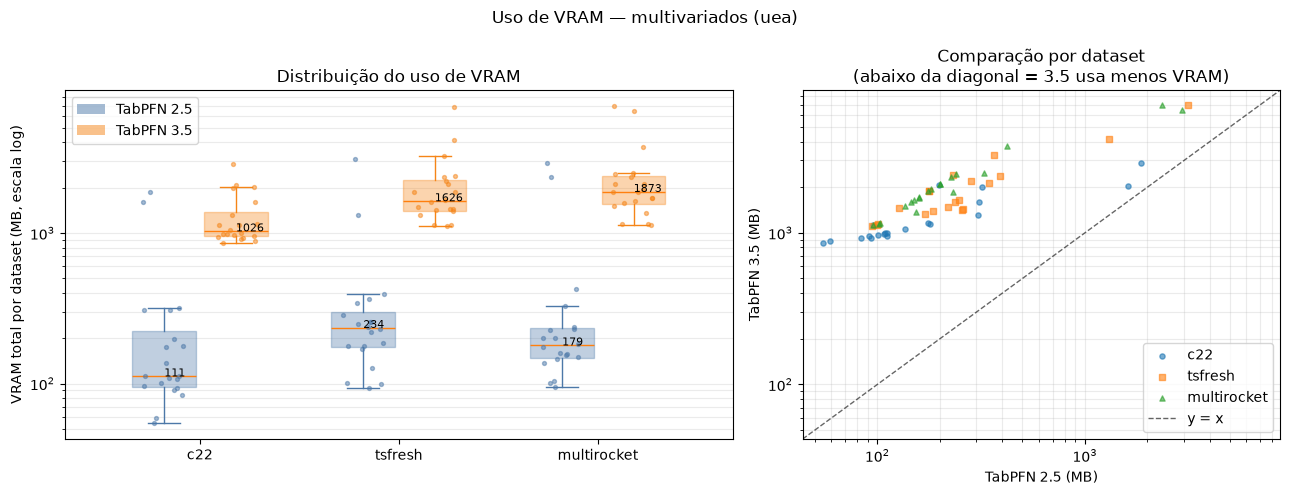

In [16]:
base = Path("./full/mv_core")
dtw_path = Path("./full/uea/accuracy/1NN-DTW-D_accuracy.csv")
stat = "vram_total_mb"
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}

# Datasets de referência do benchmark UEA
dtw = pd.read_csv(dtw_path, index_col=0)
dtw.index = dtw.index.astype(str)
uea_datasets = dtw.select_dtypes("number").mean(axis=1).dropna().index

# Carrega VRAM e filtra para os datasets do benchmark
data = {}
for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if not p.exists():
            print(f"Não encontrado: {p}")
            continue
        df = pd.read_csv(p, index_col=0)
        df.index = df.index.astype(str)
        s = df.select_dtypes("number").mean(axis=1)
        data[v, m] = s.reindex(uea_datasets).dropna()

# Resumo estatístico
summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(),
        "mediana (MB)": s.median(),
        "média (MB)": s.mean(),
        "máx (MB)": s.max()
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

print(f"\nDatasets no UEA: {len(uea_datasets)}")
for (v, m), s in data.items():
    print(f"TabPFN {v} + {m}: {s.notna().sum()}/{len(uea_datasets)}")

# Gráficos
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        y = y[y > 0]
        if not len(y):
            continue
        pos = i + (j - .5) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.0f}", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="VRAM total por dataset (MB, escala log)",
      title="Distribuição do uso de VRAM")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6, marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (MB)",
      ylabel="TabPFN 3.5 (MB)",
      title="Comparação por dataset\n(abaixo da diagonal = 3.5 usa menos VRAM)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Uso de VRAM — multivariados (uea)")
plt.tight_layout()
plt.show()

                       datasets  mediana (s)  média (s)  máx (s)  total (min)
TabPFN2.5-c22              20.0         3.93      12.94   127.67         4.31
TabPFN2.5-tsfresh          20.0         5.85      41.03   491.07        13.68
TabPFN2.5-multirocket      20.0        10.05     109.52   850.88        36.51
TabPFN3.5-c22              20.0         3.62       4.02     7.24         1.34
TabPFN3.5-tsfresh          20.0         4.45       7.01    39.83         2.34
TabPFN3.5-multirocket      20.0         7.00       7.80    19.82         2.60

Datasets no UEA: 26
TabPFN 2.5 + c22: 20/26
TabPFN 2.5 + tsfresh: 20/26
TabPFN 2.5 + multirocket: 20/26
TabPFN 3.5 + c22: 20/26
TabPFN 3.5 + tsfresh: 20/26
TabPFN 3.5 + multirocket: 20/26


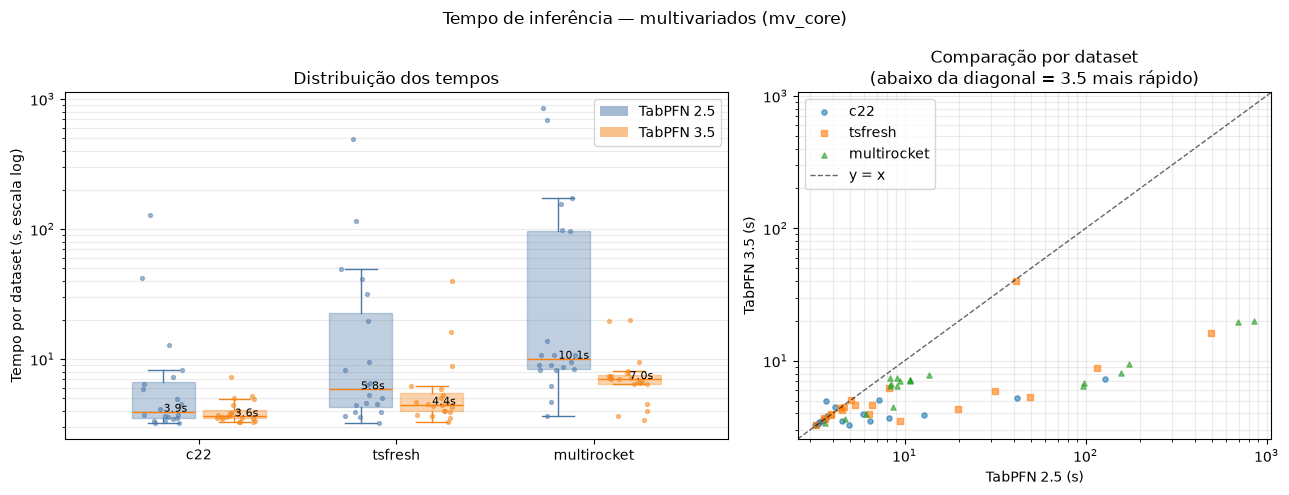

In [17]:
base, stat = Path("./full/mv_core"), "inference_time"
dtw_path = Path("./full/uea/accuracy/1NN-DTW-D_accuracy.csv")
methods, versions = ["c22", "tsfresh", "multirocket"], ["2.5", "3.5"]
colors = {"2.5": "#4C78A8", "3.5": "#F58518"}

# Datasets do UEA Benchmark
dtw = pd.read_csv(dtw_path, index_col=0)
dtw.index = dtw.index.astype(str)
uea_datasets = dtw.select_dtypes("number").mean(axis=1).dropna().index

# Carrega os tempos e filtra os datasets
data = {}
for v in versions:
    for m in methods:
        p = base / stat / f"TabPFN{v}-{m}_{stat}.csv"
        if p.exists():
            df = pd.read_csv(p, index_col=0)
            df.index = df.index.astype(str)
            s = df.select_dtypes("number").mean(axis=1)
            data[v, m] = s.reindex(uea_datasets).dropna()
        else:
            print(f"Não encontrado: {p}")

# Resumo estatístico
summary = pd.DataFrame({
    f"TabPFN{v}-{m}": {
        "datasets": s.notna().sum(), "mediana (s)": s.median(),
        "média (s)": s.mean(), "máx (s)": s.max(),
        "total (min)": s.sum()/60
    } for (v, m), s in data.items()
}).T
print(summary.round(2).to_string())

print(f"\nDatasets no UEA: {len(uea_datasets)}")
for (v, m), s in data.items():
    print(f"TabPFN {v} + {m}: {s.notna().sum()}/{len(uea_datasets)}")

# Gráficos
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5),
                           gridspec_kw={"width_ratios": [1.4, 1]})
rng, w = np.random.default_rng(0), 0.32

for j, v in enumerate(versions):
    for i, m in enumerate(methods):
        s = data.get((v, m))
        if s is None:
            continue
        y = s.dropna().to_numpy()
        y = y[y > 0]
        if not len(y):
            continue
        pos = i + (j - .5) * (w + .04)
        bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True,
                       showfliers=False)
        bp["boxes"][0].set(facecolor=colors[v], edgecolor=colors[v], alpha=.35)
        for obj in bp["whiskers"] + bp["caps"]:
            obj.set(color=colors[v])
        a.scatter(pos + rng.uniform(-w/3, w/3, len(y)), y,
                  s=8, color=colors[v], alpha=.5, zorder=3)
        a.annotate(f"{np.median(y):.1f}s", (pos, np.median(y)),
                   xytext=(w/2+.02, 0), textcoords="offset points", fontsize=8)

a.set(yscale="log", xticks=range(len(methods)), xticklabels=methods,
      ylabel="Tempo por dataset (s, escala log)",
      title="Distribuição dos tempos")
a.grid(axis="y", which="both", alpha=.25)
a.set_axisbelow(True)
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=colors[v], alpha=.5,
                                label=f"TabPFN {v}") for v in versions])

markers, vals = ["o", "s", "^"], []
for k, m in enumerate(methods):
    sx, sy = data.get(("2.5", m)), data.get(("3.5", m))
    if sx is None or sy is None:
        continue
    pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
    pair = pair[(pair > 0).all(axis=1)]
    b.scatter(pair.x, pair.y, s=14, alpha=.6, marker=markers[k], label=m)
    vals.extend(pair.to_numpy().ravel())

if vals:
    lo, hi = min(vals)*.8, max(vals)*1.25
    b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
    b.set(xlim=(lo, hi), ylim=(lo, hi))

b.set(xscale="log", yscale="log", xlabel="TabPFN 2.5 (s)",
      ylabel="TabPFN 3.5 (s)",
      title="Comparação por dataset\n(abaixo da diagonal = 3.5 mais rápido)")
b.grid(which="both", alpha=.25)
b.set_axisbelow(True)
b.legend()

fig.suptitle("Tempo de inferência — multivariados (mv_core)")
plt.tight_layout()
plt.show()